importing library and load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fakenews.csv")

df.head()

,news_id,headline,body_text,source,label
0,1,Global economy faces recession,The Prime Minister attended the inauguration c...,CNN,Real
1,2,"Earthquake hits Chittagong, panic spreads",Government sources state that an official anno...,Daily Star,Real
2,3,Breakthrough in Bangladesh's tech industry,Local administration has visited the spot for ...,BBC,Fake
3,4,Dengue situation worsens in the country,The Prime Minister attended the inauguration c...,BBC,Fake
4,5,New virus outbreak sparks fear,Government sources state that an official anno...,Reuters,Real


Identify Frequent News Sources

In [2]:
source_frequency = df['source'].value_counts()

print("News Source Frequency:")
print(source_frequency)

News Source Frequency:
source
CNN             476
Reuters         467
BBC             436
Unknown News    423
Daily Star      410
Name: count, dtype: int64


Analyse Fake and Real News by Source

In [4]:
source_analysis = pd.crosstab(
    df['source'],
    df['label']
)

print(source_analysis)

label         Fake  Real
source                  
BBC            223   213
CNN            250   226
Daily Star     200   210
Reuters        241   226
Unknown News   196   227


Calculate Fake and Real News Percentage

In [5]:
source_analysis['Total'] = source_analysis.sum(axis=1)

source_analysis['Fake_Percentage'] = (
    source_analysis['Fake'] / source_analysis['Total'] * 100
)

source_analysis['Real_Percentage'] = (
    source_analysis['Real'] / source_analysis['Total'] * 100
)

display(source_analysis)

label,Fake,Real,Total,Fake_Percentage,Real_Percentage
source,,,,,
BBC,223,213,436,51.146789,48.853211
CNN,250,226,476,52.521008,47.478992
Daily Star,200,210,410,48.780488,51.219512
Reuters,241,226,467,51.605996,48.394004
Unknown News,196,227,423,46.335697,53.664303


Analyse Source Credibility

In [7]:
source_analysis['Credibility_Score'] = (
    source_analysis['Real_Percentage']
)

source_analysis['Credibility_Category'] = np.where(
    source_analysis['Total'] < 3,
    'Insufficient Data',
    np.where(
        source_analysis['Credibility_Score'] >= 70,
        'Higher Dataset Score',
        np.where(
            source_analysis['Credibility_Score'] >= 40,
            'Moderate Dataset Score',
            'Lower Dataset Score'
        )
    )
)

display(source_analysis)

label,Fake,Real,Total,Fake_Percentage,Real_Percentage,Credibility_Score,Credibility_Category
source,,,,,,,
BBC,223,213,436,51.146789,48.853211,48.853211,Moderate Dataset Score
CNN,250,226,476,52.521008,47.478992,47.478992,Moderate Dataset Score
Daily Star,200,210,410,48.780488,51.219512,51.219512,Moderate Dataset Score
Reuters,241,226,467,51.605996,48.394004,48.394004,Moderate Dataset Score
Unknown News,196,227,423,46.335697,53.664303,53.664303,Moderate Dataset Score


Visualize Frequent News Sources


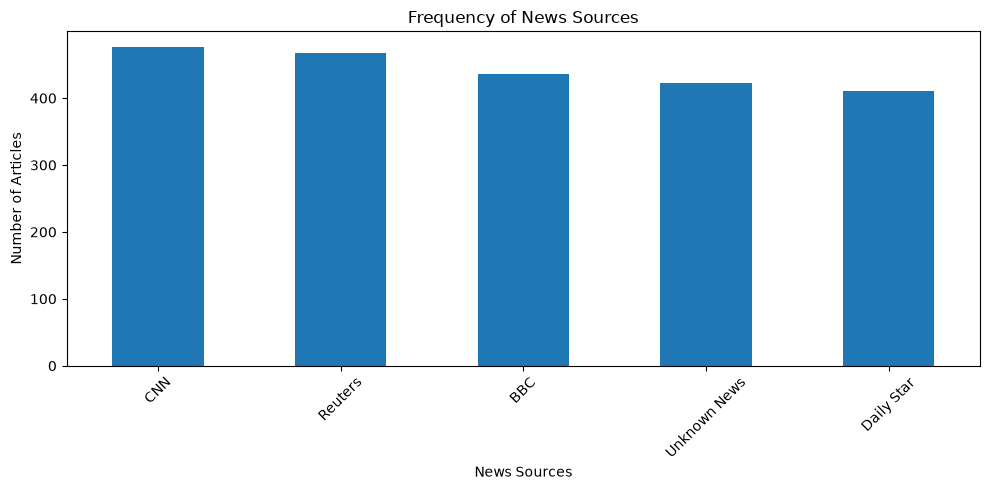

In [9]:
plt.figure(figsize=(10, 5))

source_frequency.plot(kind='bar')

plt.title("Frequency of News Sources")
plt.xlabel("News Sources")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Visualize Fake vs Real News Sources

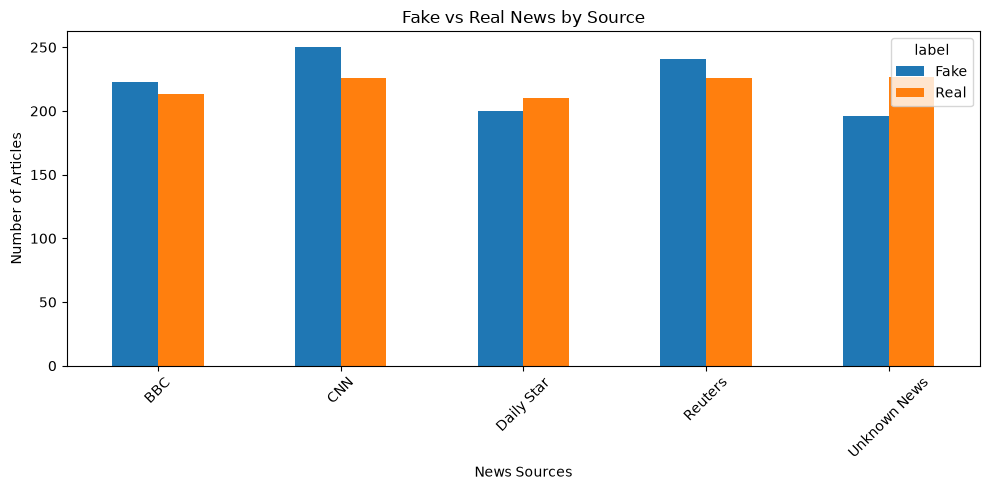

In [10]:
source_analysis[['Fake', 'Real']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Fake vs Real News by Source")
plt.xlabel("News Sources")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Visualize Credibility Scores

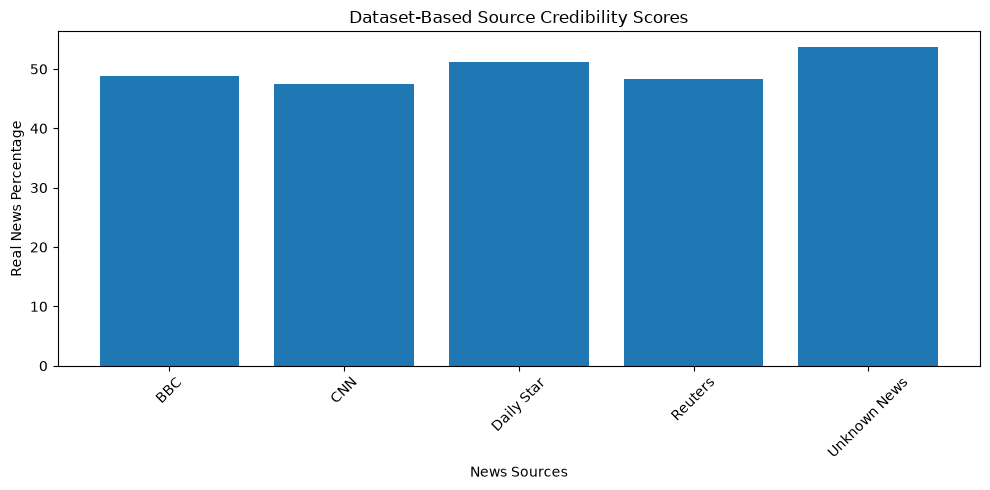

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    source_analysis.index,
    source_analysis['Credibility_Score']
)

plt.title("Dataset-Based Source Credibility Scores")
plt.xlabel("News Sources")
plt.ylabel("Real News Percentage")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Final Analysis

In [12]:
print("NEWS SOURCE CREDIBILITY ANALYSIS")

print("\nMost Frequent Sources:")
print(source_frequency.head())

print("\nSource Credibility Analysis:")
display(source_analysis)

print("\nLeast Represented Sources:")
print(source_frequency.tail())

NEWS SOURCE CREDIBILITY ANALYSIS

Most Frequent Sources:
source
CNN             476
Reuters         467
BBC             436
Unknown News    423
Daily Star      410
Name: count, dtype: int64

Source Credibility Analysis:


label,Fake,Real,Total,Fake_Percentage,Real_Percentage,Credibility_Score,Credibility_Category
source,,,,,,,
BBC,223,213,436,51.146789,48.853211,48.853211,Moderate Dataset Score
CNN,250,226,476,52.521008,47.478992,47.478992,Moderate Dataset Score
Daily Star,200,210,410,48.780488,51.219512,51.219512,Moderate Dataset Score
Reuters,241,226,467,51.605996,48.394004,48.394004,Moderate Dataset Score
Unknown News,196,227,423,46.335697,53.664303,53.664303,Moderate Dataset Score



Least Represented Sources:
source
CNN             476
Reuters         467
BBC             436
Unknown News    423
Daily Star      410
Name: count, dtype: int64
